# Turismo de sol y playa

# 1. El encargo y los datos

Prever a **12 meses** (`freq="MS"`) las pernoctaciones hoteleras mensuales de **residentes en el extranjero** en 5 destinos costeros desde enero de 2005, descargando los datos directamente desde la API JSON del INE (tabla 2078) sin subirlos al repositorio.

Consultamos una muestra pequeña (`nult=2`) para comprobar que la API responde y localizar los códigos (`COD`) de nuestros 5 destinos.

In [1]:
import requests
import pandas as pd

URL = "https://servicios.ine.es/wstempus/js/ES/DATOS_TABLA/2078"

r = requests.get(URL, params={"nult": 2}, timeout=60)
r.raise_for_status()
raw = r.json()

nombres = pd.DataFrame({
    "COD": [s["COD"] for s in raw],
    "Nombre": [s["Nombre"] for s in raw],
})

mask = (
    nombres["Nombre"].str.contains("Pernoctaciones", case=False)
    & nombres["Nombre"].str.contains("extranjero", case=False)
)
pern = nombres[mask]
nac = pern[pern["Nombre"].str.startswith("Nacional")]

print("Series totales:", len(nombres))
print("Pernoctaciones de residentes en el extranjero:", len(pern))
print("De ellas, 'Nacional.':", len(nac))
print()

for destino in ["Benidorm", "Palma", "Marbella", "Bartolom", "Adeje"]:
    print(destino)
    print(nac[nac["Nombre"].str.contains(destino, case=False)][["COD", "Nombre"]].to_string())
    print()

Series totales: 552
Pernoctaciones de residentes en el extranjero: 138
De ellas, 'Nacional.': 97

Benidorm
         COD                                                            Nombre
139  EOT2626  Nacional. Pernoctaciones. Benidorm. Residentes en el extranjero.

Palma
         COD                                                                              Nombre
191  EOT2658           Nacional. Pernoctaciones. Palma De Mallorca. Residentes en el extranjero.
431  EOT2810  Nacional. Pernoctaciones. Las Palmas De Gran Canaria. Residentes en el extranjero.

Marbella
         COD                                                            Nombre
367  EOT2762  Nacional. Pernoctaciones. Marbella. Residentes en el extranjero.

Bartolom
         COD                                                                             Nombre
435  EOT2814  Nacional. Pernoctaciones. San Bartolomé De Tirajana. Residentes en el extranjero.

Adeje
         COD                                                

Descargamos el histórico completo (`nult=400`) de las 5 series elegidas, normalizamos las fechas a hora de Madrid (`freq="MS"`) y guardamos una copia en `../data/` (ignorada en `.gitignore`).

In [2]:
from pathlib import Path
import requests
import pandas as pd

BASE = "https://servicios.ine.es/wstempus/js/ES/DATOS_SERIE/"

SERIES = {
    "EOT2626": "Benidorm",
    "EOT2658": "Palma de Mallorca",
    "EOT2762": "Marbella",
    "EOT2814": "San Bartolomé de Tirajana",
    "EOT2830": "Adeje",
}

Path("../data").mkdir(exist_ok=True)

filas = []
for cod, destino in SERIES.items():
    r = requests.get(BASE + cod, params={"nult": 400}, timeout=60)
    r.raise_for_status()
    for d in r.json()["Data"]:
        filas.append({
            "destino": destino,
            "cod": cod,
            "fecha_ms": d["Fecha"],
            "valor": d["Valor"],
            "secreto": d["Secreto"],
            "tipo_dato": d["FK_TipoDato"],
        })

df = pd.DataFrame(filas)
df["fecha"] = (
    pd.to_datetime(df["fecha_ms"], unit="ms", utc=True)
    .dt.tz_convert("Europe/Madrid")
    .dt.tz_localize(None)
    .dt.to_period("M")
    .dt.to_timestamp()
)
df = df.drop(columns="fecha_ms").sort_values(["destino", "fecha"])
df["descargado"] = pd.Timestamp.today().normalize()

df.to_parquet("../data/pernoctaciones_raw.parquet", index=False)

# ¿El tipo 2 son siempre los mismos meses en los 5 destinos?
print(df[df["tipo_dato"] == 2].groupby("destino")["fecha"].agg(["min", "max", "count"]))

                                 min        max  count
destino                                               
Adeje                     2026-01-01 2026-09-01      9
Benidorm                  2026-01-01 2026-09-01      9
Marbella                  2026-01-01 2026-09-01      9
Palma de Mallorca         2026-01-01 2026-09-01      9
San Bartolomé de Tirajana 2026-01-01 2026-09-01      9


# 2. Trampas que hay que resolver

Auditamos el calendario completo (`2005-01` a `2026-09`) para detectar huecos, ceros por el cierre COVID, secreto estadístico y datos provisionales.

In [3]:
# Qué mes falta en cada destino (frente al calendario completo)
calendario = pd.date_range("2005-01-01", "2026-09-01", freq="MS")
for destino, g in df.groupby("destino"):
    faltan = calendario.difference(g["fecha"])
    print(destino, "-> meses que faltan:", list(faltan.strftime("%Y-%m")))

# Valores nulos y ceros
print()
print("Nulos por destino:")
print(df[df["valor"].isna()].groupby("destino")["fecha"].apply(lambda s: list(s.dt.strftime("%Y-%m"))))
print()
print("Ceros por destino:")
print(df[df["valor"] == 0].groupby("destino")["fecha"].apply(lambda s: list(s.dt.strftime("%Y-%m"))))

# Entorno del COVID
print()
print(df[(df["fecha"] >= "2020-02-01") & (df["fecha"] <= "2020-07-01")]
      .pivot(index="fecha", columns="destino", values="valor"))

Adeje -> meses que faltan: []
Benidorm -> meses que faltan: []
Marbella -> meses que faltan: ['2020-05']
Palma de Mallorca -> meses que faltan: []
San Bartolomé de Tirajana -> meses que faltan: []

Nulos por destino:
destino
Adeje                                 [2020-05, 2020-06]
Benidorm                     [2020-05, 2020-06, 2021-02]
Marbella                                       [2020-06]
Palma de Mallorca                     [2020-05, 2020-06]
San Bartolomé de Tirajana             [2020-05, 2020-06]
Name: fecha, dtype: object

Ceros por destino:
destino
Adeje                        [2020-04]
Benidorm                     [2020-04]
Marbella                     [2020-04]
Palma de Mallorca            [2020-04]
San Bartolomé de Tirajana    [2020-04]
Name: fecha, dtype: object

destino        Adeje  Benidorm  Marbella  Palma de Mallorca  \
fecha                                                         
2020-02-01  823845.0  312054.0  107632.0           207239.0   
2020-03-01  358033.0  2

In [4]:
# Benidorm, febrero 2021: ¿secreto estadístico?
print(df[(df["destino"] == "Benidorm") & (df["fecha"].between("2021-01-01", "2021-03-01"))])
print()
print("Datos marcados como secretos por destino:")
print(df.groupby("destino")["secreto"].sum())

# Calendario completo: una fila por mes, una columna por destino
calendario = pd.date_range("2005-01-01", "2026-09-01", freq="MS")
completo = df.set_index(["destino", "fecha"])["valor"].unstack("destino").reindex(calendario)
completo.index.name = "fecha"

print()
print("Tamaño:", completo.shape)
print(completo.isna().sum())
print()
print(completo.loc["2020-03":"2020-07"])

      destino      cod   valor  secreto  tipo_dato      fecha descargado
192  Benidorm  EOT2626  2484.0    False          1 2021-01-01 2026-11-21
193  Benidorm  EOT2626     NaN     True          1 2021-02-01 2026-11-21
194  Benidorm  EOT2626  2006.0    False          1 2021-03-01 2026-11-21

Datos marcados como secretos por destino:
destino
Adeje                        2
Benidorm                     3
Marbella                     1
Palma de Mallorca            2
San Bartolomé de Tirajana    2
Name: secreto, dtype: int64

Tamaño: (261, 5)
destino
Adeje                        2
Benidorm                     3
Marbella                     2
Palma de Mallorca            2
San Bartolomé de Tirajana    2
dtype: int64

destino        Adeje  Benidorm  Marbella  Palma de Mallorca  \
fecha                                                         
2020-03-01  358033.0  235608.0   61237.0            97316.0   
2020-04-01       0.0       0.0       0.0                0.0   
2020-05-01       NaN       

In [5]:
sec = df[df["secreto"]].copy()
sec["fecha"] = sec["fecha"].dt.strftime("%Y-%m")
print(sec[["destino", "fecha", "valor"]].to_string(index=False))

                  destino   fecha  valor
                    Adeje 2020-05    NaN
                    Adeje 2020-06    NaN
                 Benidorm 2020-05    NaN
                 Benidorm 2020-06    NaN
                 Benidorm 2021-02    NaN
                 Marbella 2020-06    NaN
        Palma de Mallorca 2020-05    NaN
        Palma de Mallorca 2020-06    NaN
San Bartolomé de Tirajana 2020-05    NaN
San Bartolomé de Tirajana 2020-06    NaN


In [6]:
r = requests.get(BASE + "EOT2626", params={"nult": 400}, timeout=60)
r.raise_for_status()
tipos = pd.DataFrame(r.json()["Data"])

print(tipos["FK_TipoDato"].value_counts())
print()
print(tipos[["Anyo", "FK_Periodo", "FK_TipoDato"]].tail(10))

FK_TipoDato
1    252
2      9
Name: count, dtype: int64

     Anyo  FK_Periodo  FK_TipoDato
251  2025          12            1
252  2026           1            2
253  2026           2            2
254  2026           3            2
255  2026           4            2
256  2026           5            2
257  2026           6            2
258  2026           7            2
259  2026           8            2
260  2026           9            2


In [7]:
import requests
import pandas as pd

r = requests.get(
    "https://servicios.ine.es/wstempus/js/ES/DATOS_SERIE/EOT2626",
    params={"nult": 12, "tip": "A"},
    timeout=60,
)
r.raise_for_status()
d = pd.DataFrame(r.json()["Data"])
print(d.columns.tolist())
print(d.tail(12))

['Fecha', 'T3_TipoDato', 'T3_Periodo', 'Anyo', 'Valor']
                            Fecha  T3_TipoDato T3_Periodo  Anyo     Valor
0   2025-10-01T00:00:00.000+02:00   Definitivo        M10  2025  712235.0
1   2025-11-01T00:00:00.000+01:00   Definitivo        M11  2025  499684.0
2   2025-12-01T00:00:00.000+01:00   Definitivo        M12  2025  331108.0
3   2026-01-01T00:00:00.000+01:00  Provisional        M01  2026  308208.0
4   2026-02-01T00:00:00.000+01:00  Provisional        M02  2026  366479.0
5   2026-03-01T00:00:00.000+01:00  Provisional        M03  2026  539432.0
6   2026-04-01T00:00:00.000+02:00  Provisional        M04  2026  574698.0
7   2026-05-01T00:00:00.000+02:00  Provisional        M05  2026  740263.0
8   2026-06-01T00:00:00.000+02:00  Provisional        M06  2026  740743.0
9   2026-07-01T00:00:00.000+02:00  Provisional        M07  2026  835661.0
10  2026-08-01T00:00:00.000+02:00  Provisional        M08  2026  817487.0
11  2026-09-01T00:00:00.000+02:00  Provisional        M0

Convertimos abril de 2020 (`0.0`) en hueco junto con mayo y junio de 2020 para que las series sean estrictamente positivas (necesario para log/Box-Cox en E2), interpolamos linealmente y guardamos la columna `imputado` en formato Nixtla (`unique_id`, `ds`, `y`).

In [8]:
calendario = pd.date_range("2005-01-01", "2026-09-01", freq="MS")
ancho = df.pivot(index="fecha", columns="destino", values="valor").reindex(calendario)
ancho.index.name = "ds"

# Abril 2020 (0) se trata como hueco igual que mayo y junio
ancho.loc["2020-04-01":"2020-06-01"] = float("nan")
imputado = ancho.isna()

y = ancho.interpolate(method="linear", limit_area="inside")

nixtla = (
    pd.concat([y.stack().rename("y"), imputado.stack().rename("imputado")], axis=1)
    .reset_index()
    .rename(columns={"destino": "unique_id"})
    .sort_values(["unique_id", "ds"])
    .reset_index(drop=True)
)

nixtla.to_parquet("../data/pernoctaciones_nixtla.parquet", index=False)

print("Filas:", len(nixtla), "(esperadas 1305)")
print("Nulos en y:", nixtla["y"].isna().sum())
print("Mínimo de y:", nixtla["y"].min())
print(nixtla[nixtla["imputado"]].groupby("unique_id")["ds"].apply(lambda s: list(s.dt.strftime("%Y-%m"))))

Filas: 1305 (esperadas 1305)
Nulos en y: 0
Mínimo de y: 2006.0
unique_id
Adeje                                 [2020-04, 2020-05, 2020-06]
Benidorm                     [2020-04, 2020-05, 2020-06, 2021-02]
Marbella                              [2020-04, 2020-05, 2020-06]
Palma de Mallorca                     [2020-04, 2020-05, 2020-06]
San Bartolomé de Tirajana             [2020-04, 2020-05, 2020-06]
Name: ds, dtype: object


**Trampas detectadas y decisiones tomadas:**

**Series desde 2005:** De las 138 series de extranjeros, solo 97 empiezan por `Nacional.` y arrancan en enero de 2005; se descartaron los puntos añadidos en 2024 (~32 meses) y se evitó confundir *Palma de Mallorca* con *Las Palmas de Gran Canaria*.

**Fechas UTC:** La API entrega milisegundos en UTC (22:00/23:00 del día anterior); se convierten a `Europe/Madrid` y se fijan al día 1 de cada mes (`freq="MS"`).

**Cierre COVID (abr-jun 2020):** Abril de 2020 vale `0` en los cinco destinos y mayo y junio no tienen dato. Con un 0 no se puede usar log ni Box-Cox. Se tratan los tres meses como huecos y se interpolan linealmente.

**Secreto estadístico:** Mayo y junio de 2020 (en Marbella solo consta junio) y febrero de 2021 en Benidorm llegan vacíos con `secreto = True`. Se tratan como dato ausente.

**Mes que falta en Marbella:** La fila de mayo de 2020 no llega de la API. Reconstruimos un calendario mensual completo de 261 meses para todos los destinos.

**Datos provisionales:** Al pedir la serie con `tip=A`, la API etiqueta `FK_TipoDato = 1` como «Definitivo» y `2` como «Provisional». Los últimos 9 meses (ene-sep 2026) son provisionales en los 5 destinos y el INE puede revisarlos.

# 3. Exploración visual de las series

Dibujamos las 5 series completas marcando en rojo los meses imputados y con línea discontinua el inicio del conjunto de prueba (`2025-09`).

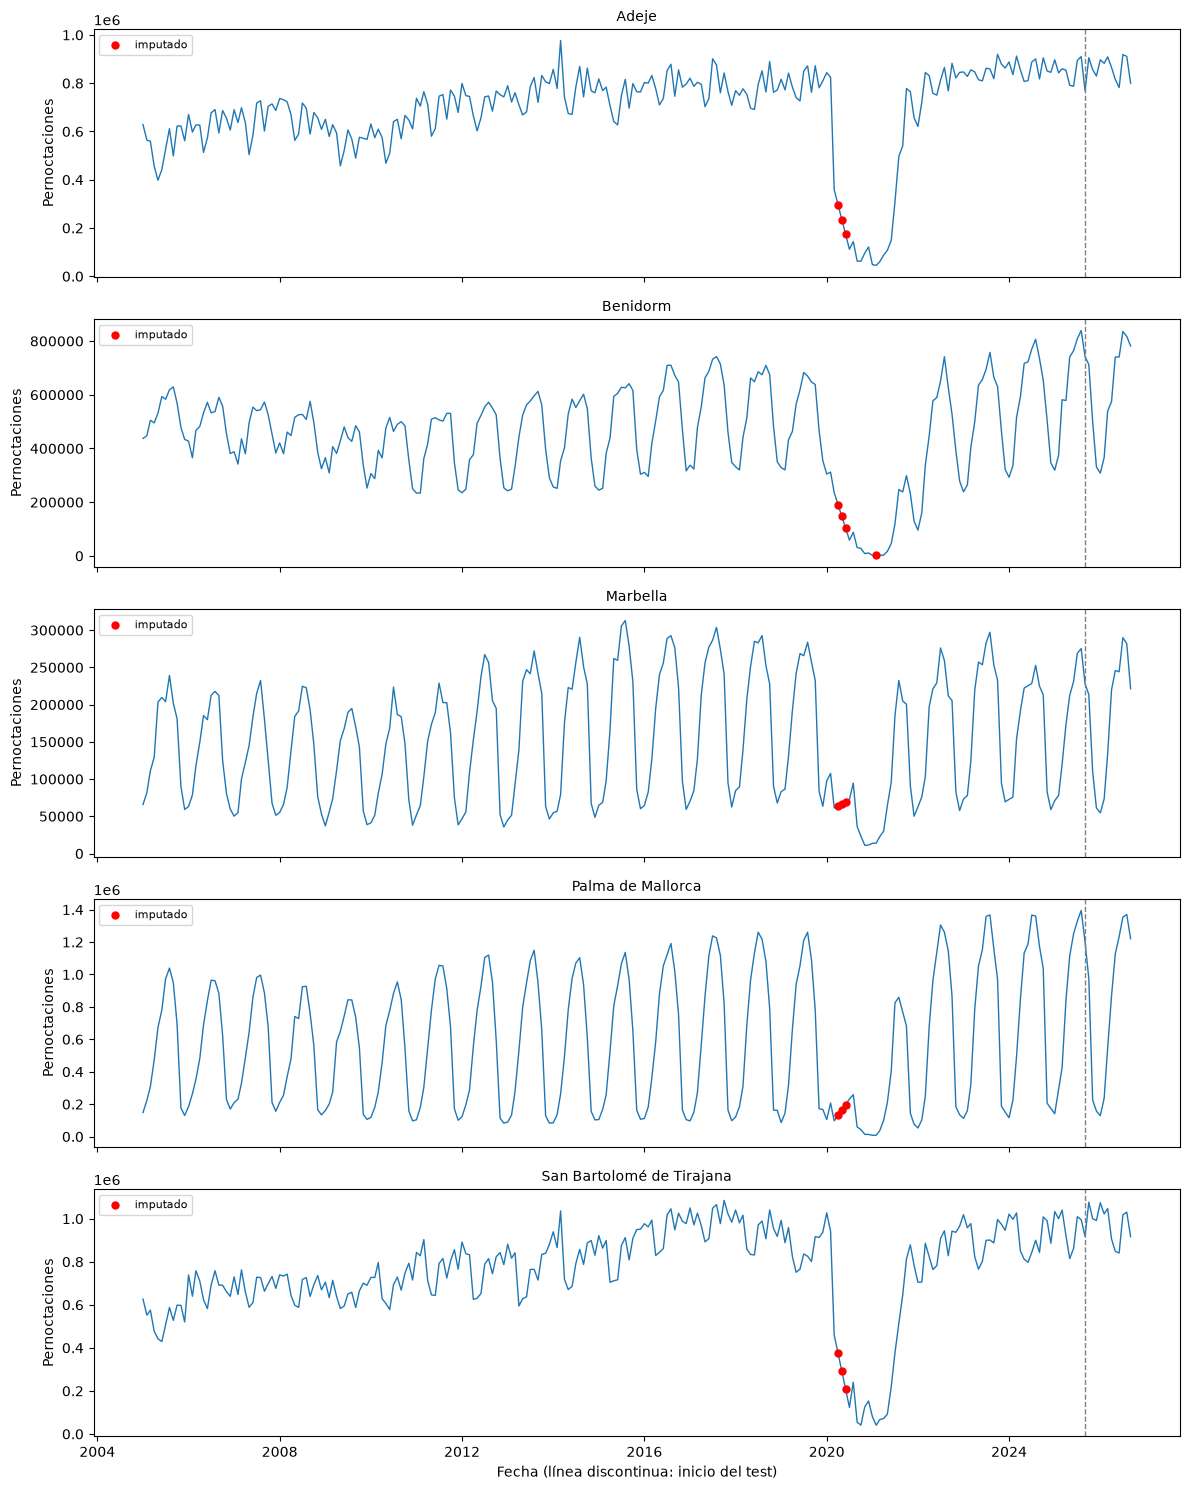

In [9]:
import matplotlib.pyplot as plt

destinos = nixtla["unique_id"].unique()
fig, ejes = plt.subplots(len(destinos), 1, figsize=(12, 3 * len(destinos)), sharex=True)

for eje, destino in zip(ejes, destinos):
    s = nixtla[nixtla["unique_id"] == destino]
    imp = s[s["imputado"]]
    eje.plot(s["ds"], s["y"], color="tab:blue", linewidth=1)
    eje.scatter(imp["ds"], imp["y"], color="red", s=25, zorder=3, label="imputado")
    eje.axvline(pd.Timestamp("2025-09-01"), color="gray", linestyle="--", linewidth=1)
    eje.set_title(destino, fontsize=10)
    eje.set_ylabel("Pernoctaciones")
    eje.legend(loc="upper left", fontsize=8)

ejes[-1].set_xlabel("Fecha (línea discontinua: inicio del test)")
plt.tight_layout()
plt.show()

**Observaciones del gráfico:**

**Estacionalidad:** Palma de Mallorca, Benidorm y Marbella tienen una estacionalidad anual muy fuerte con picos en verano; Adeje y San Bartolomé de Tirajana son mucho más planas durante el año.

**Caída COVID y recuperación:** En 2020 se ve el desplome en todos los destinos (donde caen los meses imputados) y la recuperación hasta 2022. En 2024–2026 las series vuelven a niveles similares o superiores a los previos al COVID.

# 4. Partición y modelos rival a batir

Reservamos los últimos 12 meses (`oct-2025` a `sep-2026`) como test y aplicamos una ventana rodante de 3 orígenes (`h=12`, `step_size=12`) sobre `train`, evaluando `HistoricAverage`, `Naive`, `SeasonalNaive(12)` y `RandomWalkWithDrift` con **MAE**, **RMSE** y **MASE**.

In [10]:
from functools import partial
from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, SeasonalNaive, RandomWalkWithDrift
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse, mase

# 1. Datos y partición: train hasta sep-2025, test = últimos 12 meses
df = nixtla[["unique_id", "ds", "y"]].copy()
h = 12
fecha_corte = df["ds"].max() - pd.DateOffset(months=h)
train = df[df["ds"] <= fecha_corte].copy()
test = df[df["ds"] > fecha_corte].copy()
print("Train:", len(train), "| Test:", len(test), "(esperadas 1245 y 60)")

# 2. Los cuatro rivales a batir
modelos = [HistoricAverage(), Naive(), SeasonalNaive(season_length=12), RandomWalkWithDrift()]
nombres = [m.alias for m in modelos]
sf = StatsForecast(models=modelos, freq="MS")

# 3. Ventana rodante: 3 orígenes sobre el train
cv_df = sf.cross_validation(df=train, h=h, step_size=h, n_windows=3)
print("Cortes:", sorted(cv_df["cutoff"].unique()))

metricas = [mae, rmse, partial(mase, seasonality=12)]

# 4. Evaluación por ventana: el MASE se escala con el train hasta cada corte
res = []
for corte, g in cv_df.groupby("cutoff"):
    hist = train[train["ds"] <= corte]
    e = evaluate(g.drop(columns="cutoff"), metrics=metricas, train_df=hist)
    e["cutoff"] = corte
    res.append(e)
eval_cv = pd.concat(res)

print("\n=== VENTANA RODANTE (media de los 5 destinos, por origen) ===")
print(eval_cv.groupby(["cutoff", "metric"])[nombres].mean().round(2))

# 5. Test final (oct-2025 a sep-2026)
pred_test = sf.forecast(df=train, h=h)
eval_test = evaluate(
    test.merge(pred_test, on=["unique_id", "ds"]),
    metrics=metricas,
    train_df=train,
)
print("\n=== TEST FINAL (media de los 5 destinos) ===")
print(eval_test.groupby("metric")[nombres].mean().round(2))

c:\Users\Laura\miniconda3\envs\analisis_avanzaso\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 1245 | Test: 60 (esperadas 1245 y 60)
Cortes: [Timestamp('2022-09-01 00:00:00'), Timestamp('2023-09-01 00:00:00'), Timestamp('2024-09-01 00:00:00')]

=== VENTANA RODANTE (media de los 5 destinos, por origen) ===
                   HistoricAverage      Naive  SeasonalNaive        RWD
cutoff     metric                                                      
2022-09-01 mae           216836.33  183427.82       71629.65  183579.01
           mase               2.50       2.21           0.77       2.20
           rmse          233201.53  227204.18       91864.15  228414.80
2023-09-01 mae           222906.38  167580.07       40716.28  169581.10
           mase               2.51       2.11           0.54       2.16
           rmse          242310.68  214386.14       48794.03  216701.85
2024-09-01 mae           228221.57  175858.38       30647.82  175029.98
           mase               2.64       2.18           0.37       2.17
           rmse          247077.18  224073.94       38173.75 

## Resultados de los modelos de referencia
El seasonal naïve es el mejor de los cuatro en todas las ventanas y en el test. En el test final tiene un MASE de 0.32 (MAE de unas 23 900 pernoctaciones), frente a 2.31 del naïve y del drift y 2.80 de la media histórica. Naïve y drift dan resultados casi iguales.

El MASE del seasonal naïve baja de 0.77 (ventana 1) a 0.37 (ventana 3). Creemos que se debe a que la ventana 1 está más cerca de la recuperación del COVID, pero no lo hemos comprobado.

Para E2, el modelo a batir es el seasonal naïve: un MASE de 0.32 en el test.

Desglosamos las métricas por destino para ver qué plazas presentan mayor dificultad.

In [11]:
# MASE por destino: ventana rodante (media de las 3 ventanas) y test final
mase_cv = (
    eval_cv[eval_cv["metric"] == "mase"]
    .groupby("unique_id")[nombres].mean()
)
mase_test = eval_test[eval_test["metric"] == "mase"].set_index("unique_id")[nombres]

print("=== MASE POR DESTINO · ventana rodante (media de 3 ventanas) ===")
print(mase_cv.round(2))
print("\n=== MASE POR DESTINO · test final ===")
print(mase_test.round(2))

# Evolución del seasonal naïve por origen y destino
sn = eval_cv[eval_cv["metric"] == "mase"].pivot(
    index="unique_id", columns="cutoff", values="SeasonalNaive"
)
sn.columns = sn.columns.strftime("%Y-%m")
sn["test"] = mase_test["SeasonalNaive"]
print("\n=== MASE del SeasonalNaive por destino y origen ===")
print(sn.round(2))

# MAE por destino en el test, para ver el error en pernoctaciones
mae_test = eval_test[eval_test["metric"] == "mae"].set_index("unique_id")[nombres]
print("\n=== MAE POR DESTINO · test final ===")
print(mae_test.round(0))

# Mejor modelo por destino en el test
print("\nMejor modelo por destino (test):")
print(mase_test.idxmin(axis=1))

=== MASE POR DESTINO · ventana rodante (media de 3 ventanas) ===
                           HistoricAverage  Naive  SeasonalNaive   RWD
unique_id                                                             
Adeje                                 1.48   0.47           0.33  0.45
Benidorm                              2.37   2.06           0.83  2.05
Marbella                              2.74   2.80           0.70  2.85
Palma de Mallorca                     4.80   4.78           0.52  4.84
San Bartolomé de Tirajana             1.37   0.72           0.44  0.71

=== MASE POR DESTINO · test final ===
                           HistoricAverage  Naive  SeasonalNaive   RWD
unique_id                                                             
Adeje                                 1.55   0.85           0.15  0.81
Benidorm                              2.70   2.22           0.27  2.23
Marbella                              3.01   2.72           0.59  2.73
Palma de Mallorca                     5.02  

## Resultados por destino

El seasonal naïve es el mejor modelo en los cinco destinos, tanto en la ventana rodante como en el test. En el test su MASE va de 0.15 (Adeje) a 0.59 (Marbella). Marbella es el destino más difícil y su MASE no mejora año a año como en los demás. En Benidorm, en la ventana 1 (sep-2022), el MASE del seasonal naïve fue 1.17, el único valor por encima de 1.

El naïve y el drift se defienden mejor en Adeje y San Bartolomé de Tirajana (MASE entre 0.7 y 0.85), donde la serie es más plana, y fallan mucho en Palma (MASE 5). La media de los cinco destinos esconde estas diferencias, por eso damos también los resultados por destino.

Para E2, el modelo a batir es el seasonal naïve, con especial atención a Marbella.

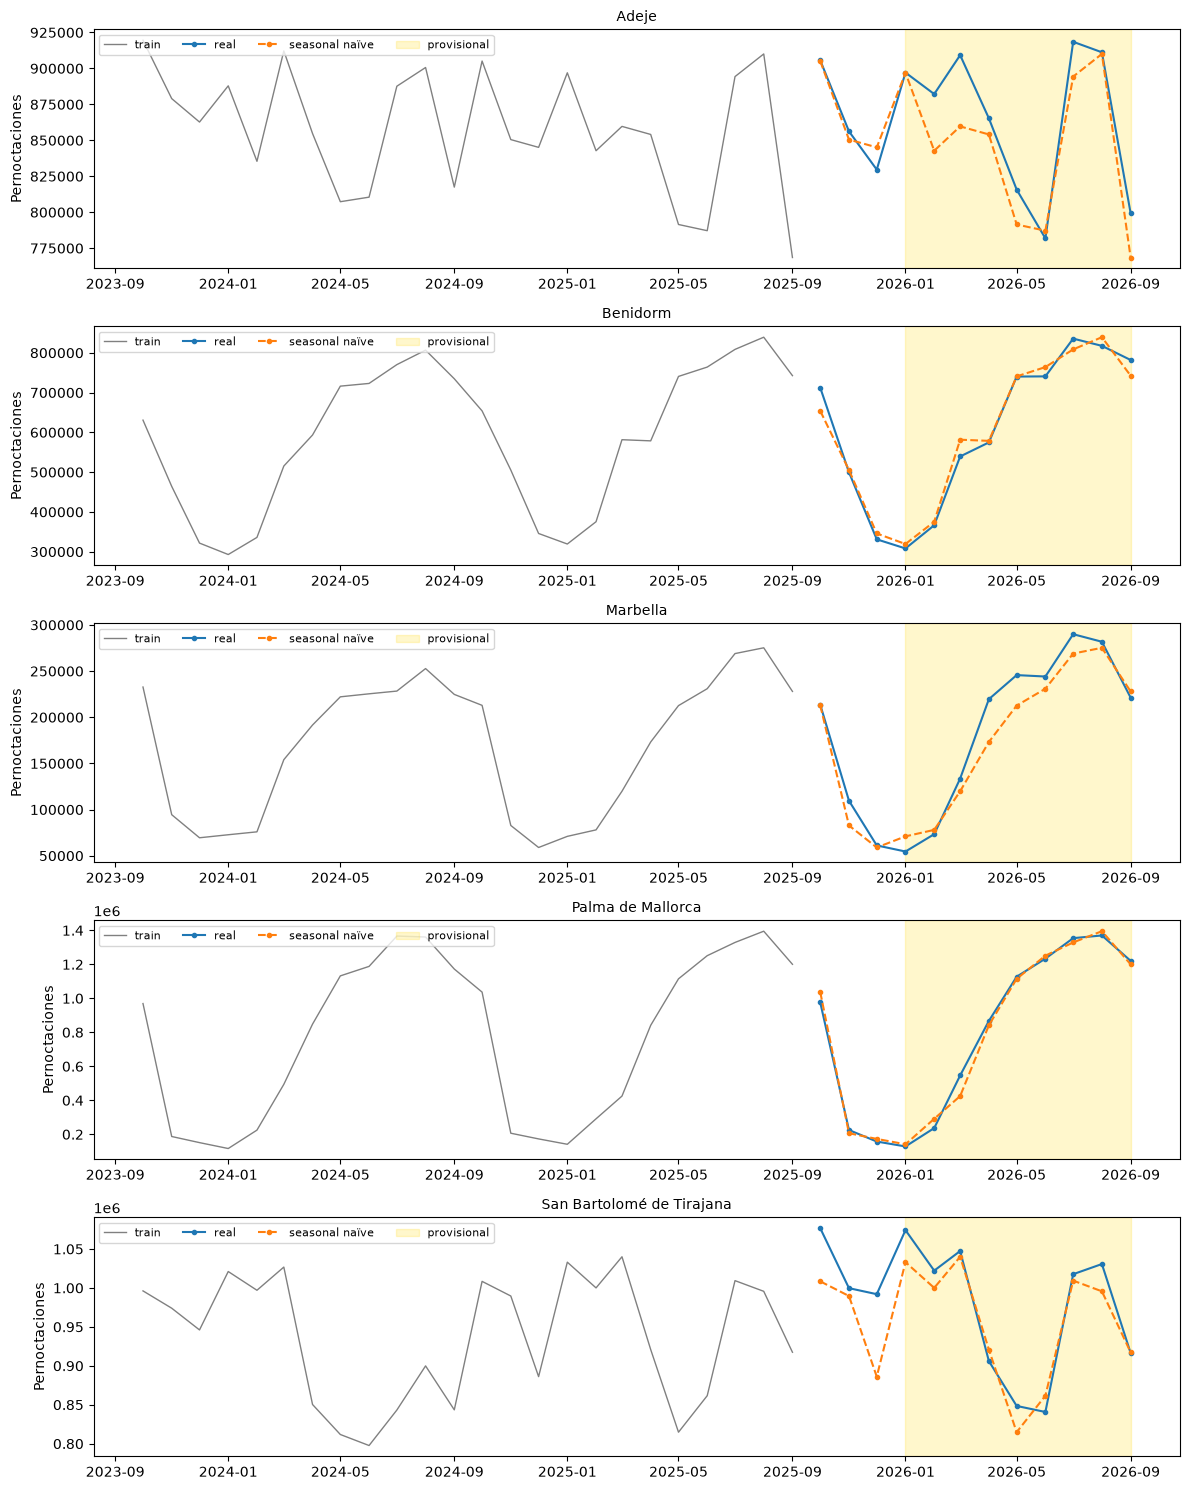

unique_id  Adeje  Benidorm  Marbella  Palma de Mallorca  \
ds                                                        
2025-10      0.1       8.2       0.3                6.2   
2025-11      0.7       1.1      24.5                8.3   
2025-12      1.9       4.4       3.6                9.8   
2026-01      0.0       3.6      30.1                9.9   
2026-02      4.5       2.4       6.3               23.1   
2026-03      5.4       7.8      10.3               22.2   
2026-04      1.3       0.7      21.1                3.0   
2026-05      3.0       0.1      13.5                1.1   
2026-06      0.7       3.2       5.4                1.4   
2026-07      2.6       3.2       7.2                1.9   
2026-08      0.1       2.7       2.3                1.8   
2026-09      3.9       5.0       3.0                1.7   

unique_id  San Bartolomé de Tirajana  
ds                                    
2025-10                          6.3  
2025-11                          1.0  
2025-12          

In [12]:
import matplotlib.pyplot as plt

comp = test.merge(pred_test[["unique_id", "ds", "SeasonalNaive"]], on=["unique_id", "ds"])
destinos = comp["unique_id"].unique()

fig, ejes = plt.subplots(len(destinos), 1, figsize=(12, 3 * len(destinos)))

for eje, destino in zip(ejes, destinos):
    hist = train[(train["unique_id"] == destino) & (train["ds"] >= "2023-10-01")]
    c = comp[comp["unique_id"] == destino]
    eje.plot(hist["ds"], hist["y"], color="gray", linewidth=1, label="train")
    eje.plot(c["ds"], c["y"], color="tab:blue", marker="o", markersize=3, label="real")
    eje.plot(c["ds"], c["SeasonalNaive"], color="tab:orange", marker="o",
             markersize=3, linestyle="--", label="seasonal naïve")
    eje.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-09-01"),
                color="gold", alpha=0.2, label="provisional")
    eje.set_title(destino, fontsize=10)
    eje.set_ylabel("Pernoctaciones")
    eje.legend(loc="upper left", fontsize=8, ncol=4)

plt.tight_layout()
plt.show()

# Error porcentual por mes (valor absoluto), para ver dónde falla
comp["error_%"] = (100 * (comp["y"] - comp["SeasonalNaive"]).abs() / comp["y"]).round(1)
tabla = comp.pivot(index="ds", columns="unique_id", values="error_%")
tabla.index = tabla.index.strftime("%Y-%m")
print(tabla)

## Predicciones del test

Gráficamente, el seasonal naïve sigue bien la forma estacional en los cinco destinos. Los mayores errores porcentuales caen en meses de poco volumen (noviembre a marzo en Palma) y en el arranque de temporada de Marbella, donde el modelo se queda por debajo del valor real (errores de hasta el 30%). En los meses provisionales (ene-sep 2026) no vemos errores claramente mayores que en oct-dic 2025, aunque son pocos puntos y no es una prueba.

## Variables externas (plan para E2)

En E1 no usamos variables externas. Para E2 solo valen las que conoceríamos el día de la predicción:

- **Semana Santa.** Su fecha se conoce para todo el horizonte. Puede explicar parte de los errores de marzo y abril, que es donde más falla el seasonal naïve en Marbella y Palma. No lo hemos comprobado.
- **Indicador `imputado`.** Marca abril-junio de 2020 (COVID) y febrero de 2021 en Benidorm (secreto estadístico). Sirve para que esos meses no distorsionen el modelo. En el futuro vale siempre 0.
- **Pasajeros de Aena, tipo de cambio e IPH.** A 12 meses vista no se conocen. Solo las usaríamos con un retardo de 12 meses, o con previsiones oficiales publicadas antes de la fecha de corte.